# Analysis of September temperatures in Bangalore

This code is based on the code obtained from the ECMWF code for France. In Bangalore, we have been experiencing elevated temperatures and especially so in the month of September.

The idea here is to show using the original data formats (netcdf/.nc) how long it can take to download the data.

This code also shows how to work with the xarray package. This package is not only useful for old data formats but also for the newer formats (zarr, cog, etc) and shows some basic commands to answer our question whether it has been hotter in Bangalore during the month of September in 2026.

This code is based on this ECMWF tutorial: [Analysis of September 2020 European Heatwave using ERA5 Climate Reanalysis Data from C3S](https://ecmwf-projects.github.io/copernicus-training-c3s/reanalysis-heatwave.html)

## Creating an account with the CDS

Whether you work with the older formats or with the newer formats, you will need to create an account with the [Climate Data Store](https://cds.climate.copernicus.eu/).

You will also need an API key. You can find this in your account information if you click on "Your profile".

![logo](https://github.com/EllenB/grss_oct_talk/blob/main/images/cds_01.PNG?raw=1)

Then, you need to grab the API key:



There are several ways that you can proceed with using the API key. The easiest and fastest is to directly paste it in the code below (please see below).

![api](https://github.com/EllenB/grss_oct_talk/blob/main/images/cds_02.png?raw=1)


## Finding the right data

We want to look at daily data for the month of september for temperature for Bangalore.

The CDS has many data. For this example, we need daily data and this across the month of September across several years across the latitude and longitudes of Bangalore.

The minimum and maximum longitude and latitude for Bangalore are approximately:

- longitude minimum and maximum: 77.440784, 77.7722854
- latitude minimum and maximum: 12.8335167, 13.1572602

For simplicity, we will round the numbers.

This was obtained the using a [geojson file for Bangalore](https://data.opencity.in/dataset/gba-wards-delimitation-2025/resource/9013d656-8051-4e2d-9648-46efd0d86d3d) which you can find here and then using the [geojson.io](https://geojson.io/) and look at the corner points. I am sure there are other ways!

In order to find the right dataset, we can go to the [CDS website](https://cds.climate.copernicus.eu/datasets) with an overview of the datasets. We would like to have daily data. More specifically, we select [ERA5 hourly data on single levels from 1940 to present](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels?tab=overview) similar to the example in the original tutorial for Lille, France.

## Installing packages

In order to do this type of analysis using the older way/formats (grib, netcdf (.nc) and obtain the data from the ECWMF,

#### Install CDS API

To install the CDS API, run the following command. We use an exclamation mark to pass the command to the shell (not to the Python interpreter).

In [1]:
!pip install cdsapi cartopy --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 53.5 MB/s eta 0:00:00


#### Import libraries

We will be working with data in NetCDF format. To best handle this data we will use libraries for working with multidimensional arrays, in particular Xarray. We will also need libraries for plotting and viewing data, in this case we will use Matplotlib and Cartopy.

In [2]:
# CDS API
import cdsapi
import os

# Libraries for working with multidimensional arrays
import numpy as np
import xarray as xr

# Libraries for plotting and visualising data
import matplotlib.path as mpath
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.feature as cfeature

# Disable warnings for data download via API
import urllib3
urllib3.disable_warnings()

/tmp/ipykernel_3172/1862420430.py:13: DeprecationWarning: The LONGITUDE_FORMATTER module-level attribute was deprecated in Cartopy 0.26. Use LongitudeFormatter instead.
  from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
/tmp/ipykernel_3172/1862420430.py:13: DeprecationWarning: The LATITUDE_FORMATTER module-level attribute was deprecated in Cartopy 0.26. Use LatitudeFormatter instead.
  from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER


#### Enter your CDS API key

We will request data from the Climate Data Store (CDS) programmatically with the help of the CDS API. Let us make use of the option to manually set the CDS API credentials. First, you have to define two variables: `URL` and `KEY` which build together your CDS API key. The string of characters that make up your KEY include your personal User ID and CDS API key. To obtain these, first register or login to the CDS (https://cds.climate.copernicus.eu), then visit https://cds.climate.copernicus.eu/how-to-api and copy the string of characters listed after "key:". Replace the `#########` below with this string.

In [3]:
URL = 'https://cds.climate.copernicus.eu/api'
KEY = 'fill in your key here'

Here we specify a data directory in which we will download our data and all output files that we will generate:

In [ ]:
DATADIR = './'

Navigate to the [ERA5 hourly data on single levels from 1940 to present](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels?tab=overview) of the CDS website, click on the "Download" and fill in the following values:

![img34](https://github.com/EllenB/grss_oct_talk/blob/main/images/cds_3_4.PNG?raw=1)

![img56](https://github.com/EllenB/grss_oct_talk/blob/main/images/cds_5_6.PNG?raw=1)

![img7](https://github.com/EllenB/grss_oct_talk/blob/main/images/cds_07.PNG?raw=1)

After clicking on "Show API request, the following code shows. Follow the example from the tutorial to generate the code that can pull the data:

![img8](https://github.com/EllenB/grss_oct_talk/blob/main/images/cds_08.PNG?raw=1)

Using the code of the tutorial:

In [ ]:
c = cdsapi.Client(url=URL, key=KEY)
c.retrieve(
    'reanalysis-era5-single-levels',
    {
        'product_type': 'reanalysis',
        'data_format': 'netcdf_legacy',
        'variable': '2m_temperature',
        'year': [

            '1979', '1980', '1981',
            '1982', '1983', '1984',
            '1985', '1986', '1987',
            '1988', '1989', '1990',
            '1991', '1992', '1993',
            '1994', '1995', '1996',
            '1997', '1998', '1999',
            '2000', '2001', '2002',
            '2003', '2004', '2005',
            '2006', '2007', '2008',
            '2009', '2010', '2011',
            '2012', '2013', '2014',
            '2015', '2016', '2017',
            '2018', '2019', '2020',
            '2021', '2022', '2023',
             '2024', '2025', '2026'
        ],
        'month': '09',
        'day': [
            '01', '02', '03',
            '04', '05', '06',
            '07', '08', '09',
            '10', '11', '12',
            '13', '14', '15',
            '16', '17', '18',
            '19', '20', '21',
            '22', '23', '24',
            '25', '26', '27',
            '28', '29', '30',
        ],
        'time': [
            '00:00', '01:00', '02:00',
            '03:00', '04:00', '05:00',
            '06:00', '07:00', '08:00',
            '09:00', '10:00', '11:00',
            '12:00', '13:00', '14:00',
            '15:00', '16:00', '17:00',
            '18:00', '19:00', '20:00',
            '21:00', '22:00', '23:00',
        ],
        'area': [14, 77, 12, 78],
    },
    f'{DATADIR}Bangalore_hourly_Sep.nc')

2026-10-21 10:53:57,836 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**
INFO:ecmwf.datastores.legacy_client:[2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 

cc9bb79ebf09eac03ccff82b36432f61.nc:   0%|          | 0.00/6.07M [00:00<?, ?B/s]

'./Bangalore_hourly_Sep.nc'

In order to make sure the download is working fine, you can see the status in the CDS website under "Your requests":

![img9](https://github.com/EllenB/grss_oct_talk/blob/main/images/cds_09.PNG?raw=1)

In [ ]:
file_path = f'{DATADIR}Bangalore_hourly_Sep.nc'

Downloading this dataset took nearly one hour! In order to see this, you can again go to your CDS account to see the time (or alternatively you could have used the time Python package. We can see the time also here in CDS dashboard:

![img12](https://github.com/EllenB/grss_oct_talk/blob/main/images/cds_12.PNG?raw=1)

Running these Python lines for downloading works similarly on a local computer (but of course you would have to install Python locally, VScode (or other), install the packages. For easy of use and showing, the scripts are done in Google Colab here.

At this point in Google Colab, the .nc file can be found in the "Files". You can also download the data and save the data on a local disk from Google Colab if you go to the "Files". Please remember that the runtime may stop so do not wait!!

In [ ]:
size_bytes = os.path.getsize(file_path)
size_gb = size_bytes / 1e6

print(f"File size: {size_gb:.3f} MB")

File size: 6.360 MB


#### Looking at the data

Whether we access data here using the CDS api with the (older) NetCDF format or will use newer formats which we will see later (zarr, cog, etc.) we will have to use a Python library called "xarray" to process the data.

xarray works like a 3D cube that can hold different variables over time. In this example, we only have the variable for the temperature. Alternatively, we could have several variables such as wind, temperature, humidity, etc all in one cube.

More documentation and tutorials, you can find here on the [xarray project page](https://tutorial.xarray.dev/intro.html).

In [ ]:
# Create Xarray Dataset
ds = xr.open_dataset(file_path)

We can inspect the newly downloaded dataset. You can click on the different "buckets" on the right to expand the data.



In [ ]:
ds

<xarray.Dataset> Size: 25MB
Dimensions:    (time: 34560, expver: 2, latitude: 9, longitude: 5)
Coordinates:
  * time       (time) datetime64[ns] 276kB 1979-09-01 ... 2026-09-30T23:00:00
  * expver     (expver) int32 8B 1 5
  * latitude   (latitude) float32 36B 14.0 13.75 13.5 13.25 ... 12.5 12.25 12.0
  * longitude  (longitude) float32 20B 77.0 77.25 77.5 77.75 78.0
Data variables:
    t2m        (time, expver, latitude, longitude) float64 25MB ...
Attributes:
    Conventions:  CF-1.6
    history:      2026-10-21 11:55:08 GMT by grib_to_netcdf-2.42.0: grib_to_n...

"expver" means experiment version here and ranges from 1-5 with value 1 as the main ERA5 reanalysis data and 5 — preliminary ERA5 data. Although we have to be careful with the latest data, let' proceed anyway with this for now.

Have quick look at the time values:

In [ ]:
ds.time.values

array(['1979-09-01T00:00:00.000000000', '1979-09-01T01:00:00.000000000',
       '1979-09-01T02:00:00.000000000', ...,
       '2026-09-30T21:00:00.000000000', '2026-09-30T22:00:00.000000000',
       '2026-09-30T23:00:00.000000000'], dtype='datetime64[ns]')

In [ ]:
ds.expver.values

array([1, 5], dtype=int32)

The first variables seem to be version 1. While the "ds" variable is a dataset and can contain several variables such as wind, humidity, etc. In general, we work with is called a "DataArray" which contains only one variable.

In [ ]:
ver1= ds["t2m"].sel(expver=1)
ver1

<xarray.DataArray 't2m' (time: 34560, latitude: 9, longitude: 5)> Size: 12MB
array([[[294.958382, 295.309867, ..., 296.120554, 295.960222],
        [294.622464, 294.91324 , ..., 294.926939, 294.972081],
        ...,
        [295.473934, 296.553916, ..., 295.599086, 295.659483],
        [293.558048, 294.676946, ..., 296.272791, 295.676917]],

       [[294.889268, 295.113733, ..., 295.941854, 295.943722],
        [294.604096, 294.797428, ..., 294.951533, 295.031855],
        ...,
        [295.111865, 296.303301, ..., 295.551143, 295.498529],
        [293.736748, 294.725201, ..., 296.086308, 295.551143]],

       ...,

       [[       nan,        nan, ...,        nan,        nan],
        [       nan,        nan, ...,        nan,        nan],
        ...,
        [       nan,        nan, ...,        nan,        nan],
        [       nan,        nan, ...,        nan,        nan]],

       [[       nan,        nan, ...,        nan,        nan],
        [       nan,        nan, ...,        nan,        nan],
        ...,
        [       nan,        nan, ...,        nan,        nan],
        [       nan,        nan, ...,        nan,        nan]]])
Coordinates:
  * time       (time) datetime64[ns] 276kB 1979-09-01 ... 2026-09-30T23:00:00
  * latitude   (latitude) float32 36B 14.0 13.75 13.5 13.25 ... 12.5 12.25 12.0
  * longitude  (longitude) float32 20B 77.0 77.25 77.5 77.75 78.0
    expver     int32 4B 1
Attributes:
    units:      K
    long_name:  2 metre temperature

The later variables seem to be variable 5 (as the "nan" is at the beginning.

In [ ]:
ver5= ds["t2m"].sel(expver=5)
ver5

<xarray.DataArray 't2m' (time: 34560, latitude: 9, longitude: 5)> Size: 12MB
array([[[       nan,        nan, ...,        nan,        nan],
        [       nan,        nan, ...,        nan,        nan],
        ...,
        [       nan,        nan, ...,        nan,        nan],
        [       nan,        nan, ...,        nan,        nan]],

       [[       nan,        nan, ...,        nan,        nan],
        [       nan,        nan, ...,        nan,        nan],
        ...,
        [       nan,        nan, ...,        nan,        nan],
        [       nan,        nan, ...,        nan,        nan]],

       ...,

       [[296.428764, 296.540218, ..., 296.94058 , 297.276499],
        [295.778409, 295.907297, ..., 295.891731, 296.292093],
        ...,
        [295.165101, 295.360301, ..., 295.692484, 296.268744],
        [294.217743, 294.358461, ..., 296.725767, 296.645446]],

       [[296.170366, 296.289291, ..., 296.807023, 297.189951],
        [295.490746, 295.598153, ..., 295.912589, 296.168186],
        ...,
        [295.267838, 295.424123, ..., 295.660417, 296.168186],
        [294.203422, 294.293395, ..., 296.560765, 296.635172]]])
Coordinates:
  * time       (time) datetime64[ns] 276kB 1979-09-01 ... 2026-09-30T23:00:00
  * latitude   (latitude) float32 36B 14.0 13.75 13.5 13.25 ... 12.5 12.25 12.0
  * longitude  (longitude) float32 20B 77.0 77.25 77.5 77.75 78.0
    expver     int32 4B 5
Attributes:
    units:      K
    long_name:  2 metre temperature

From where do we have version 5?

In [ ]:
ver5_subset = ver5.dropna(
    dim="time",
    how="any"
)

In [ ]:
print("Original shape:", ver5.shape)
print("Subset shape:", ver5_subset.shape)

Original shape: (34560, 9, 5)
Subset shape: (720, 9, 5)


We notice that the data for September 2026 are "provisional".

In [ ]:
ver5_subset.time

<xarray.DataArray 'time' (time: 720)> Size: 6kB
array(['2026-09-01T00:00:00.000000000', '2026-09-01T01:00:00.000000000',
       '2026-09-01T02:00:00.000000000', ..., '2026-09-30T21:00:00.000000000',
       '2026-09-30T22:00:00.000000000', '2026-09-30T23:00:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 6kB 2026-09-01 ... 2026-09-30T23:00:00
    expver   int32 4B 5
Attributes:
    long_name:  time

If you uncomment the following line, you also see that the data are in Kelvin:

In [ ]:
## ver5_subset

<xarray.DataArray 't2m' (time: 720, latitude: 9, longitude: 5)> Size: 259kB
array([[[296.793013, 296.941514, ..., 297.052657, 297.140762],
        [296.460831, 296.6112  , ..., 296.124912, 296.330075],
        ...,
        [296.193403, 296.834108, ..., 297.361179, 298.230395],
        [294.384613, 295.089761, ..., 298.208913, 299.062563]],

       [[296.934665, 297.089082, ..., 297.116478, 297.176875],
        [296.657276, 296.803909, ..., 296.225781, 296.378018],
        ...,
        [296.170988, 296.821343, ..., 297.366471, 298.262772],
        [294.34881 , 295.071393, ..., 298.212026, 299.057893]],

       ...,

       [[296.428764, 296.540218, ..., 296.94058 , 297.276499],
        [295.778409, 295.907297, ..., 295.891731, 296.292093],
        ...,
        [295.165101, 295.360301, ..., 295.692484, 296.268744],
        [294.217743, 294.358461, ..., 296.725767, 296.645446]],

       [[296.170366, 296.289291, ..., 296.807023, 297.189951],
        [295.490746, 295.598153, ..., 295.912589, 296.168186],
        ...,
        [295.267838, 295.424123, ..., 295.660417, 296.168186],
        [294.203422, 294.293395, ..., 296.560765, 296.635172]]])
Coordinates:
  * time       (time) datetime64[ns] 6kB 2026-09-01 ... 2026-09-30T23:00:00
  * latitude   (latitude) float32 36B 14.0 13.75 13.5 13.25 ... 12.5 12.25 12.0
  * longitude  (longitude) float32 20B 77.0 77.25 77.5 77.75 78.0
    expver     int32 4B 5
Attributes:
    units:      K
    long_name:  2 metre temperature

We run this line to conver the data into Celsius:

In [ ]:
t2m_sep_2026_C = ver5_subset - 273.15
t2m_sep_2026_C

<xarray.DataArray 't2m' (time: 720, latitude: 9, longitude: 5)> Size: 259kB
array([[[23.64301296, 23.79151437, 24.16043298, 23.90265694,
         23.99076155],
        [23.31083054, 23.4611999 , 23.23486756, 22.97491225,
         23.18007458],
        [22.81084464, 22.70748517, 22.48488871, 22.37530276,
         22.58824818],
        ...,
        [23.43006753, 23.21120695, 22.47119046, 22.42822779,
         23.71119285],
        [23.04340347, 23.68410769, 23.83821293, 24.21117875,
         25.08039459],
        [21.23461264, 21.93976087, 23.70558902, 25.05891325,
         25.9125629 ]],

       [[23.78466525, 23.93908182, 24.28465115, 23.9664783 ,
         24.02687511],
        [23.50727581, 23.65390929, 23.39613324, 23.07578113,
         23.22801843],
        [23.06581877, 22.9624593 , 22.7065512 , 22.56801214,
         22.72803253],
...
        [22.50325681, 22.21030118, 21.35104771, 21.14214949,
         22.27474519],
        [22.01510121, 22.21030118, 22.2669621 , 22.5424836 ,
         23.11874381],
        [21.06774312, 21.20846144, 22.66358852, 23.57576703,
         23.49544551]],

       [[23.02036551, 23.13929117, 23.58292748, 23.65702252,
         24.0399507 ],
        [22.34074582, 22.44815251, 22.69223031, 22.76258947,
         23.01818624],
        [21.75670252, 21.53192679, 21.76635355, 21.83858066,
         22.10631906],
        ...,
        [22.54964404, 22.24485812, 21.3719064 , 21.1082152 ,
         22.14336658],
        [22.11783804, 22.27412255, 22.291868  , 22.51041725,
         23.01818624],
        [21.05342223, 21.14339478, 22.48333209, 23.41076546,
         23.48517183]]])
Coordinates:
  * time       (time) datetime64[ns] 6kB 2026-09-01 ... 2026-09-30T23:00:00
  * latitude   (latitude) float32 36B 14.0 13.75 13.5 13.25 ... 12.5 12.25 12.0
  * longitude  (longitude) float32 20B 77.0 77.25 77.5 77.75 78.0
    expver     int32 4B 5
Attributes:
    units:      K
    long_name:  2 metre temperature

Spatially averaged temperature time series for Bangalore across the latitude and longitude:

In [ ]:
## Just a simple check for the time variable
## t2m_sep_2026_C.time

Remember that we have hourly data for each day in September. We will want to compute the maximum temperature for each day and this over our small area of interest. As mentioned in this [tutorial](https://ecmwf-projects.github.io/copernicus-training-c3s/reanalysis-heatwave.html), sizes of each data point change as per the latitude. In theory, we need to correct for this when we avarage. Please see the tutorial for more detail but for simplicity, we will drop this step here.

In [ ]:
# weights = np.cos(np.deg2rad(t2m_sep_2026_C.latitude))
# weights

In [ ]:
t2m_sep_2026_C

<xarray.DataArray 't2m' (time: 720, latitude: 9, longitude: 5)> Size: 259kB
array([[[23.64301296, 23.79151437, 24.16043298, 23.90265694,
         23.99076155],
        [23.31083054, 23.4611999 , 23.23486756, 22.97491225,
         23.18007458],
        [22.81084464, 22.70748517, 22.48488871, 22.37530276,
         22.58824818],
        ...,
        [23.43006753, 23.21120695, 22.47119046, 22.42822779,
         23.71119285],
        [23.04340347, 23.68410769, 23.83821293, 24.21117875,
         25.08039459],
        [21.23461264, 21.93976087, 23.70558902, 25.05891325,
         25.9125629 ]],

       [[23.78466525, 23.93908182, 24.28465115, 23.9664783 ,
         24.02687511],
        [23.50727581, 23.65390929, 23.39613324, 23.07578113,
         23.22801843],
        [23.06581877, 22.9624593 , 22.7065512 , 22.56801214,
         22.72803253],
...
        [22.50325681, 22.21030118, 21.35104771, 21.14214949,
         22.27474519],
        [22.01510121, 22.21030118, 22.2669621 , 22.5424836 ,
         23.11874381],
        [21.06774312, 21.20846144, 22.66358852, 23.57576703,
         23.49544551]],

       [[23.02036551, 23.13929117, 23.58292748, 23.65702252,
         24.0399507 ],
        [22.34074582, 22.44815251, 22.69223031, 22.76258947,
         23.01818624],
        [21.75670252, 21.53192679, 21.76635355, 21.83858066,
         22.10631906],
        ...,
        [22.54964404, 22.24485812, 21.3719064 , 21.1082152 ,
         22.14336658],
        [22.11783804, 22.27412255, 22.291868  , 22.51041725,
         23.01818624],
        [21.05342223, 21.14339478, 22.48333209, 23.41076546,
         23.48517183]]])
Coordinates:
  * time       (time) datetime64[ns] 6kB 2026-09-01 ... 2026-09-30T23:00:00
  * latitude   (latitude) float32 36B 14.0 13.75 13.5 13.25 ... 12.5 12.25 12.0
  * longitude  (longitude) float32 20B 77.0 77.25 77.5 77.75 78.0
    expver     int32 4B 5
Attributes:
    units:      K
    long_name:  2 metre temperature

Compute the mean over the longitude and latitude. Ideally, we would have to correct for latitude as mentioned above.

In [ ]:
bangalore_t2m_mean = t2m_sep_2026_C.mean(["longitude", "latitude"])
bangalore_t2m_mean

<xarray.DataArray 't2m' (time: 720)> Size: 6kB
array([22.99941688, 23.19335773, 24.03084621, 24.4387979 , 24.97237217,
       27.05531467, 29.00079045, 29.25725202, 30.30435131, 30.74971719,
       29.3918684 , 29.14384716, 28.70892101, 28.45403681, 27.89610319,
       25.79338818, 25.44544586, 24.72798305, 24.45154142, 24.06613649,
       23.14533085, 22.66142309, 22.10692787, 22.0530066 , 23.36188072,
       23.38412998, 24.29849468, 24.6825713 , 25.23610488, 26.89240243,
       29.23438702, 29.66763895, 31.01310398, 31.42005251, 30.13329622,
       29.93169681, 29.56237694, 29.30228327, 28.46033247, 26.389836  ,
       25.56215767, 24.65496726, 24.11125767, 23.86492451, 23.06409612,
       22.37846442, 21.99576455, 21.7723033 , 23.20307103, 23.45721496,
       24.16684625, 24.59074463, 25.0901494 , 26.90232328, 29.3694185 ,
       30.01062776, 30.4325475 , 30.51474388, 29.01329875, 28.91515568,
       28.62517492, 28.53798353, 27.98460215, 26.10645531, 25.86860399,
       24.88540216, 24.57485329, 24.08637945, 23.30229336, 22.7854683 ,
       22.46694954, 22.22276797, 23.38263563, 23.49971411, 24.02005366,
       24.44465079, 25.12106038, 26.91035543, 29.26144451, 29.90790476,
       30.881926  , 31.12028928, 30.49430721, 30.44762941, 30.31814641,
       30.1145061 , 29.18243055, 26.76061564, 26.50187103, 25.2022121 ,
       24.78182822, 24.34960711, 23.73284715, 23.22736119, 22.63123853,
       22.37281908, 23.23400277, 23.21682462, 24.24444196, 24.78478233,
...
       22.59265514, 22.08927236, 21.16955981, 21.02337603, 22.68990576,
       22.87736415, 24.09251598, 24.6682504 , 25.48862992, 27.84805556,
       30.3088067 , 30.92674278, 32.28990483, 32.63849746, 31.67090333,
       31.62737336, 31.30354826, 30.50224942, 29.2533155 , 27.03258112,
       26.50793838, 25.37340556, 24.98337228, 24.54096743, 24.28155175,
       23.8090246 , 23.52955276, 23.18729037, 24.42548017, 24.35281029,
       25.30181494, 25.66608445, 25.97811384, 27.53169532, 29.96467637,
       30.4451319 , 31.40972349, 31.66312716, 30.07444912, 29.75161334,
       29.40652829, 28.74960756, 27.81788484, 25.2735329 , 25.15763054,
       24.20761582, 24.1673928 , 24.11344386, 23.80889315, 23.76747326,
       23.77309093, 23.60813086, 24.31179166, 24.248842  , 24.5807546 ,
       24.41322093, 24.87425677, 26.34201668, 28.02000312, 28.44634366,
       29.6112686 , 30.09868394, 29.62096807, 29.52833888, 29.22424479,
       28.69233091, 27.83854981, 25.95849352, 25.7068471 , 25.15216508,
       24.96082552, 24.58335588, 24.05046653, 23.85978421, 23.62930088,
       23.50719971, 24.33552836, 24.26523147, 24.68481974, 25.02811295,
       25.75263244, 27.68321311, 30.08517249, 30.69558146, 31.62228149,
       31.6401238 , 29.81138749, 29.10903425, 27.0427787 , 26.80325315,
       26.52731656, 24.50567024, 24.12375213, 23.52937288, 23.52376213,
       23.34711705, 22.70615685, 22.53405018, 22.18150028, 22.08364777])
Coordinates:
  * time     (time) datetime64[ns] 6kB 2026-09-01 ... 2026-09-30T23:00:00
    expver   int32 4B 5
Attributes:
    units:      K
    long_name:  2 metre temperature

In [ ]:
bangalore_t2m_mean.time

<xarray.DataArray 'time' (time: 720)> Size: 6kB
array(['2026-09-01T00:00:00.000000000', '2026-09-01T01:00:00.000000000',
       '2026-09-01T02:00:00.000000000', ..., '2026-09-30T21:00:00.000000000',
       '2026-09-30T22:00:00.000000000', '2026-09-30T23:00:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 6kB 2026-09-01 ... 2026-09-30T23:00:00
    expver   int32 4B 5
Attributes:
    long_name:  time

In [ ]:
bangalore_2026_max = bangalore_t2m_mean.groupby('time.day').max('time')
bangalore_2026_max

<xarray.DataArray 't2m' (day: 30)> Size: 240B
array([30.74971719, 31.42005251, 30.51474388, 31.12028928, 33.40165568,
       32.84338998, 32.85421021, 32.75951937, 31.68783243, 32.14868147,
       32.16303004, 33.09079549, 32.06832536, 32.75525078, 33.52541724,
       33.60252175, 33.2670739 , 32.54488588, 32.92553794, 30.62989215,
       30.72085402, 30.81925999, 27.6643884 , 29.52465142, 29.27878178,
       31.71988493, 32.63849746, 31.66312716, 30.09868394, 31.6401238 ])
Coordinates:
  * day      (day) int64 240B 1 2 3 4 5 6 7 8 9 ... 22 23 24 25 26 27 28 29 30
    expver   int32 4B 5
Attributes:
    units:      K
    long_name:  2 metre temperature

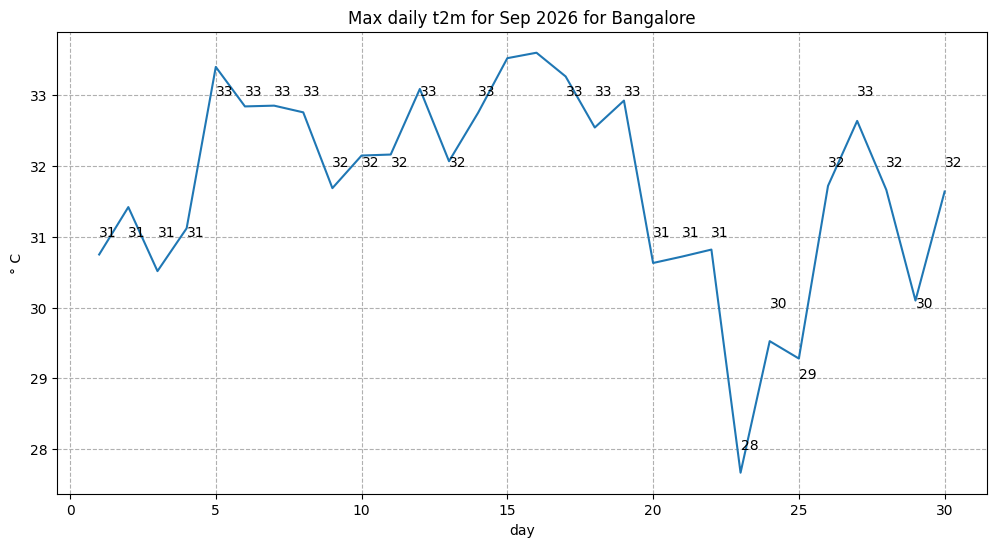

In [ ]:
fig, ax = plt.subplots(1, 1, figsize = (12, 6))

ax.plot(bangalore_2026_max.day, bangalore_2026_max)
ax.set_title('Max daily t2m for Sep 2026 for Bangalore')
ax.set_ylabel('° C')
ax.set_xlabel('day')
ax.grid(linestyle='--')
for i,j in zip(bangalore_2026_max.day, np.around(bangalore_2026_max.values, 0).astype(int)):
    ax.annotate(str(j),xy=(i,j))
fig.savefig(f'{DATADIR}max_t2_bangalore.png')


In [ ]:
print('The maximum temperature in September 2026 in Bangalore was',
      np.around(bangalore_2026_max.max().values, 1), 'degrees Celsius.')

The maximum temperature in September 2026 in Bangalore was 33.6 degrees Celsius.


## Comparing with the long-term temperature values

Select the data prior to 2026 (for September). Here, we do the same analysis as the data with the version before 2026. These data actually match the data with the version 1 but we noticed tha the later data were missing above. Hence, we restrict the data prior to 2026 (September). We can simply do so by dropping the missing data:

In [ ]:
ver1_subset = ver1.dropna(
    dim="time",
    how="any"
)
ver1_subset.time

<xarray.DataArray 'time' (time: 33840)> Size: 271kB
array(['1979-09-01T00:00:00.000000000', '1979-09-01T01:00:00.000000000',
       '1979-09-01T02:00:00.000000000', ..., '2025-09-30T21:00:00.000000000',
       '2025-09-30T22:00:00.000000000', '2025-09-30T23:00:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 271kB 1979-09-01 ... 2025-09-30T23:00:00
    expver   int32 4B 1
Attributes:
    long_name:  time

Again, compute the mean over the latitude and longitude:

In [ ]:
t2m_sep_before_C = ver1_subset - 273.15
t2m_sep_before_C

<xarray.DataArray 't2m' (time: 33840, latitude: 9, longitude: 5)> Size: 12MB
array([[[21.80838226, 22.15986674, 22.9742896 , 22.97055371,
         22.810222  ],
        [21.47246396, 21.76324032, 21.7906368 , 21.77693856,
         21.8220805 ],
        [21.10728123, 21.01326147, 21.04065796, 20.96656291,
         21.01730868],
        ...,
        [21.87282627, 22.43134103, 21.79281607, 21.30248121,
         21.97836501],
        [22.32393434, 23.40391634, 23.09944174, 22.44908648,
         22.50948328],
        [20.40804815, 21.52694561, 23.03095052, 23.12279102,
         22.52691741]],

       [[21.73926839, 21.96373279, 22.69409825, 22.7918539 ,
         22.79372184],
        [21.45409586, 21.64742789, 21.71373984, 21.80153313,
         21.88185466],
        [21.04968634, 21.16114024, 21.22153704, 21.04003531,
         21.12004551],
...
        [21.8037124 , 21.51667193, 20.88001491, 20.95410996,
         22.24890532],
        [21.79001416, 22.12406451, 22.25482048, 22.73924019,
         23.65515458],
        [20.13563989, 20.38781211, 22.11223421, 23.61623912,
         24.39548239]],

       [[21.55154019, 21.71560779, 22.15893277, 22.11410215,
         22.40705778],
        [21.23305602, 21.36972713, 21.26232045, 21.21748983,
         21.68229615],
        [20.71750393, 20.59826695, 20.49490747, 20.66489022,
         21.13561169],
        ...,
        [22.0359599 , 21.67264511, 20.94601554, 20.94196834,
         22.17854616],
        [22.05339403, 22.36783099, 22.36191584, 22.66483382,
         23.47334153],
        [20.42268037, 20.68232435, 22.13745143, 23.35815175,
         23.85626971]]])
Coordinates:
  * time       (time) datetime64[ns] 271kB 1979-09-01 ... 2025-09-30T23:00:00
  * latitude   (latitude) float32 36B 14.0 13.75 13.5 13.25 ... 12.5 12.25 12.0
  * longitude  (longitude) float32 20B 77.0 77.25 77.5 77.75 78.0
    expver     int32 4B 1
Attributes:
    units:      K
    long_name:  2 metre temperature

Again, compute over the latitude-longitude the mean and this for each day and hour:

In [ ]:
bangalore_t2m_mean_before = t2m_sep_before_C.mean(["longitude", "latitude"])
## bangalore_t2m_mean_before
bangalore_t2m_mean_before.time

<xarray.DataArray 'time' (time: 33840)> Size: 271kB
array(['1979-09-01T00:00:00.000000000', '1979-09-01T01:00:00.000000000',
       '1979-09-01T02:00:00.000000000', ..., '2025-09-30T21:00:00.000000000',
       '2025-09-30T22:00:00.000000000', '2025-09-30T23:00:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 271kB 1979-09-01 ... 2025-09-30T23:00:00
    expver   int32 4B 1
Attributes:
    long_name:  time

Now, compute the maximum values for each of the days in September for the entire period 1979-2025:

In [ ]:
bangalore_max = bangalore_t2m_mean_before.resample(time='D').max().dropna('time')
bangalore_max

<xarray.DataArray 't2m' (time: 1410)> Size: 11kB
array([30.19005399, 28.31481284, 28.71493993, ..., 28.73312124,
       29.03180522, 29.2968524 ])
Coordinates:
  * time     (time) datetime64[ns] 11kB 1979-09-01 1979-09-02 ... 2025-09-30
    expver   int32 4B 1
Attributes:
    units:      K
    long_name:  2 metre temperature

We see that we have resampled and only have data for each day with the maximum temperature and this for the entire period 1978-2025:

In [ ]:
bangalore_max.time

<xarray.DataArray 'time' (time: 1410)> Size: 11kB
array(['1979-09-01T00:00:00.000000000', '1979-09-02T00:00:00.000000000',
       '1979-09-03T00:00:00.000000000', ..., '2025-09-28T00:00:00.000000000',
       '2025-09-29T00:00:00.000000000', '2025-09-30T00:00:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 11kB 1979-09-01 1979-09-02 ... 2025-09-30
    expver   int32 4B 1
Attributes:
    long_name:  time

For each day, compute several statistics over the year:

In [ ]:
bangalore_max_max = bangalore_max.groupby('time.day').max()
bangalore_max_min = bangalore_max.groupby('time.day').min()
bangalore_max_mid = bangalore_max.groupby('time.day').quantile(0.5)

The following data array prints out for each day the hottest temperature taken over all the years:

In [ ]:
bangalore_max_max

<xarray.DataArray 't2m' (day: 30)> Size: 240B
array([31.87553988, 31.44403828, 31.61621413, 32.10240493, 30.66376417,
       31.93323854, 31.65874095, 31.46236487, 30.8762945 , 31.29537082,
       31.26625168, 32.01216256, 32.31962587, 32.22951495, 31.73188819,
       31.06601518, 31.39306421, 31.13886493, 31.74120715, 31.37497284,
       31.66132148, 32.31811076, 31.55776829, 31.94914372, 31.51468109,
       31.40438255, 31.65640257, 31.98775478, 31.46867436, 31.46764353])
Coordinates:
  * day      (day) int64 240B 1 2 3 4 5 6 7 8 9 ... 22 23 24 25 26 27 28 29 30
    expver   int32 4B 1
Attributes:
    units:      K
    long_name:  2 metre temperature

/tmp/ipykernel_4366/1280713628.py:5: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "bo-" (-> color='b'). The keyword argument will take precedence.
  ax.plot(bangalore_2026_max.day.day, bangalore_2026_max, 'bo-', color='darkred', label='Daily max t2m Sep 2026')


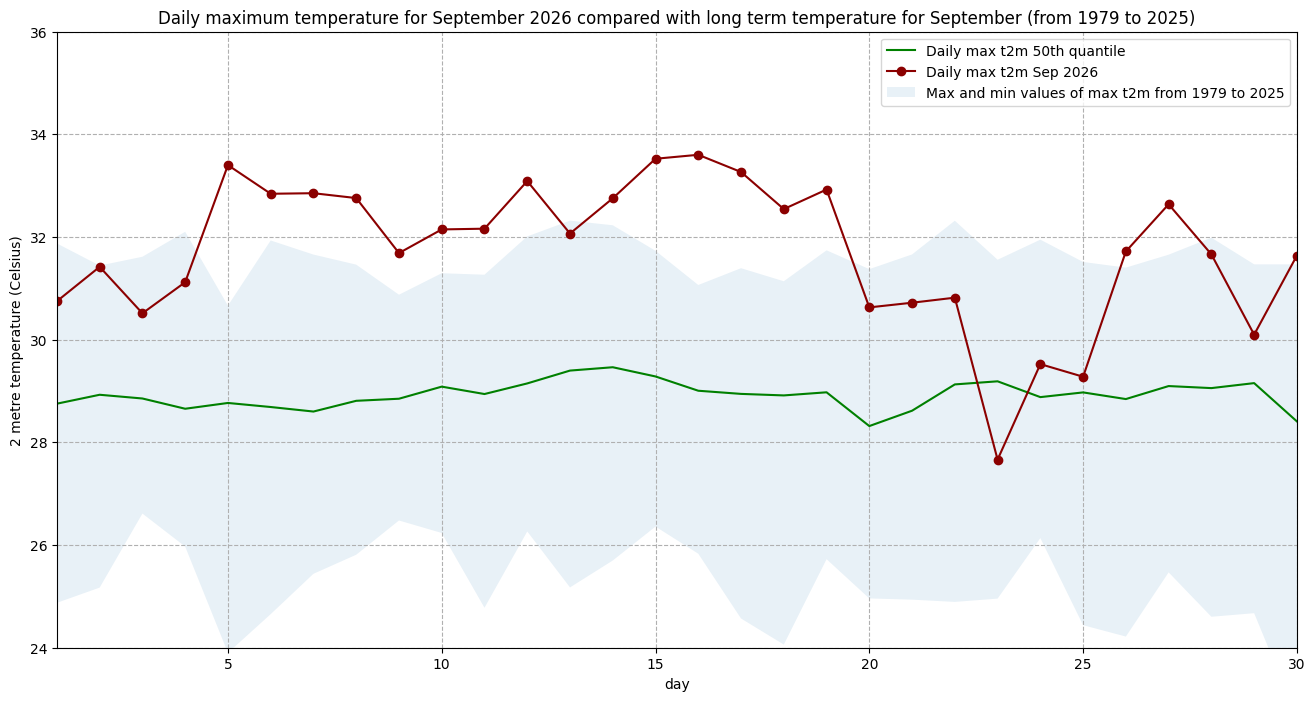

In [ ]:
fig = plt.figure(figsize=(16,8))
ax = plt.subplot()

ax.plot(bangalore_2026_max.day.day, bangalore_max_mid, color='green', label='Daily max t2m 50th quantile')
ax.plot(bangalore_2026_max.day.day, bangalore_2026_max, 'bo-', color='darkred', label='Daily max t2m Sep 2026')
ax.fill_between(bangalore_2026_max.day, bangalore_max_max, bangalore_max_min, alpha=0.1,
                label='Max and min values of max t2m from 1979 to 2025')

ax.set_xlim(1,30)
ax.set_ylim(24,36)
ax.set_title('Daily maximum temperature for September 2026 compared with long term temperature for September (from 1979 to 2025)')
ax.set_ylabel('2 metre temperature (Celsius)')
ax.set_xlabel('day')
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels)
ax.grid(linestyle='--')

fig.savefig(f'{DATADIR}max_t2m_Sep_bangalore_comparison.png')

## References

https://ecmwf-training.github.io/c3s-training/

https://ecmwf-projects.github.io/copernicus-training-c3s/reanalysis-heatwave.html

<hr>